# Boostrap

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

/home/nesper94/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Herramientas básicas

### Muestreo aleatorio con reemplazo
Para hacer un muestreo con reemplazo de una lista de valores:

In [2]:
valores = [1, 2, 3, 4, 5]

# Muestreo con reemplazo (replace=True)
muestra = np.random.choice(valores, size=len(valores), replace=True)
muestra

array([1, 3, 2, 1, 4])

Si tenemos una tabla de Pandas:

In [3]:
tabla = pd.DataFrame({'x': [1,2,3,4,5], 'y': ['a','b','c','d','e']})

tabla.sample(3, replace=True)

,x,y
3,4,d
0,1,a
3,4,d


### Cálculo de percentiles

Para calcular un determinado percentil de una lista de valores con `numpy`:

In [4]:
valores = [28, 32, 35, 40, 45, 50, 55, 60, 95, 120]

# Calcular el percentil 90 (el 90% de los valores están por debajo de este número)
p90 = np.percentile(valores, 90)

p90

97.49999999999999

Para calcular un determinado percentil usando Pandas:

In [5]:
# Crear un DataFrame de ejemplo
df = pd.DataFrame({'valores': [28, 32, 35, 40, 45, 50, 55, 60, 95, 120]})

# Calcular el percentil 90 (0.9)
p90 = df['valores'].quantile(0.9)
print(p90)

97.49999999999999


## Ejercicio bootstrap

Las tortugas tienen *determinación sexual ambiental*, en ellas,
el sexo está determinado por la temperatura de incubación de los
huevos. Mayores temperaturas hacen que nazcan más hembras, mientras
que temperaturas frías hacen que nazcan más machos.

Un grupo de biólogos están interesados en estudiar el efecto del
calentamiento global sobre las poblaciones de tortugas, así que
fueron a campo y capturaron 21 tortugas, obteniendo los siguientes
datos:

In [20]:
datos = pd.DataFrame({
    'sexo': [
        'Hembra', 'Macho', 'Hembra', 'Macho', 'Hembra',
        'Hembra', 'Macho', 'Hembra', 'Macho', 'Hembra',
        'Macho', 'Hembra', 'Hembra', 'Macho', 'Hembra',
        'Macho', 'Hembra', 'Hembra', 'Macho', 'Hembra',
        'Macho'
    ],
    'temperatura': [
        30.2, 27.1, 29.8, 26.9, 30.5, 29.7, 27.4,
        30.1, 26.5, 29.9, 27.0, 30.3, 29.5, 26.8,
        30.4, 27.2, 29.6, 30.0, 26.7, 29.8, 27.3
    ],
    'longitud': [
        24.5, 21.3, 25.1, 20.8, 26.2, 24.8, 22.1,
        25.7, 19.9, 24.2, 21.7, 26.0, 23.9, 20.5,
        25.4, 21.9, 24.6, 25.3, 20.2, 24.9, 21.5
    ]
})

datos

,sexo,temperatura,longitud
0,Hembra,30.2,24.5
1,Macho,27.1,21.3
2,Hembra,29.8,25.1
3,Macho,26.9,20.8
4,Hembra,30.5,26.2
5,Hembra,29.7,24.8
6,Macho,27.4,22.1
7,Hembra,30.1,25.7
8,Macho,26.5,19.9
9,Hembra,29.9,24.2


<Axes: xlabel='sexo', ylabel='longitud'>

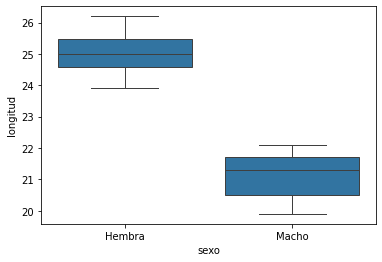

In [22]:
sns.boxplot(datos, x='sexo', y='longitud')

In [7]:
tortugas = pd.DataFrame({'longitud_caparazón_cm': [29.2, 33.8, 32.8, 36.4, 31.1, 28.5, 31.5, 31.3, 33.1, 30.1, 26.7,
       29.5, 27.7, 30.7, 26.2, 28.8, 28.7, 31.9, 32.4, 31.6, 33.4],
                        'sexo': ['macho', 'hembra', 'hembra', 'hembra', 'macho', 'macho', 'macho',
       'macho', 'hembra', 'hembra', 'hembra', 'hembra', 'hembra',
       'hembra', 'hembra', 'macho', 'hembra', 'hembra', 'hembra',
       'hembra', 'macho']})
tortugas

,longitud_caparazón_cm,sexo
0,29.2,macho
1,33.8,hembra
2,32.8,hembra
3,36.4,hembra
4,31.1,macho
5,28.5,macho
6,31.5,macho
7,31.3,macho
8,33.1,hembra
9,30.1,hembra


Produzca 10.000 muestras de bootstrap a partir de esta muestra y
calcule para cada una la proporción de hembras ($ P_h $):

In [8]:
bootstrap_ph = []
for i in range(10000):
    muestra_de_bootstrap = np.random.choice(tortugas['sexo'], size=21, replace=True)
    ph = np.sum(muestra_de_bootstrap == 'hembra')/len(muestra_de_bootstrap)
    bootstrap_ph.append(ph)

Grafique la distribución de bootstrap del estadístico $ P_h $:

<Axes: ylabel='Count'>

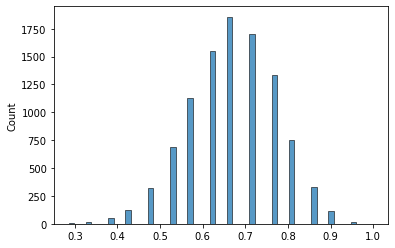

In [9]:
sns.histplot(bootstrap_ph)

## Intervalos de confianza mediante Bootstrap

Calcule un intervalo de confianza de $ \approx 95\% $ para la proporción de hembras usando el método del error estándar:

In [10]:
# Error estándar
se = np.std(bootstrap_ph)
se

0.10213372408941075

In [11]:
# Límite inferior del intervalo
14/21 - 2*se

0.46239921848784515

In [12]:
# Límite superior del intervalo
14/21 + 2*se

0.8709341148454881

Ahora calcule el intervalo de confianza del $ 95\% $ usando el método de los percentiles:

In [13]:
np.percentile(bootstrap_ph, 2.5)

0.47619047619047616

In [14]:
np.percentile(bootstrap_ph, 97.5)

0.8571428571428571

Calcule un intervalo de confianza para el tamaño de las tortugas
usando la distribución t de Student:

Calcule un intervalo de confianza para el tamaño de las tortugas
a partir de una distribución de bootstrap usando el método de
los percentiles:

Calcule un intervalo de confianza para el tamaño
de las tortugas a partir de una distribución de bootstrap
usando el método del error estándar:

Basándose en estos intervalos de confianza, ¿se puede concluir que
la proporción de hembras es diferente de 0.5?

## Ejercicio 2

Vaya a [este enlace](https://i2d.humboldt.org.co/ceiba/resource.do?r=rrbb_reptilia_bojonawi_2020&request_locale=es) y descargue los
datos allí depositados.

1. ¿De qué datos se trata?
2. ¿En qué formato están?

Importe estos datos como una tabla de Pandas:

In [15]:
reptiles = pd.read_csv('../datos/dwca-rrbb_reptilia_bojonawi_2020-v2.0/occurrence.txt', sep='\t')

In [16]:
reptiles.columns

Index(['id', 'institutionCode', 'collectionCode', 'basisOfRecord',
       'occurrenceID', 'recordNumber', 'recordedBy', 'individualCount', 'sex',
       'lifeStage', 'samplingProtocol', 'eventDate', 'eventTime', 'habitat',
       'country', 'countryCode', 'stateProvince', 'county', 'locality',
       'minimumElevationInMeters', 'maximumElevationInMeters',
       'verbatimLatitude', 'verbatimLongitude', 'verbatimCoordinateSystem',
       'verbatimSRS', 'decimalLatitude', 'decimalLongitude', 'geodeticDatum',
       'coordinateUncertaintyInMeters', 'identifiedBy', 'dateIdentified',
       'scientificName', 'kingdom', 'phylum', 'class', 'order', 'family',
       'genus', 'specificEpithet', 'taxonRank', 'scientificNameAuthorship'],
      dtype='object')

In [17]:
reptiles[['scientificName', 'sex', 'individualCount']]

,scientificName,sex,individualCount
0,Paleosuchus palpebrosus,Macho,1
1,Podocnemis expansa,NaN,1
2,Peltocephalus dumerilianus,NaN,1
3,Paleosuchus palpebrosus,Hembra,1
4,Paleosuchus palpebrosus,Macho,1
5,Paleosuchus palpebrosus,Hembra,1
6,Paleosuchus palpebrosus,Hembra,1
7,Paleosuchus palpebrosus,Hembra,1
8,Paleosuchus palpebrosus,NaN,1
9,Paleosuchus palpebrosus,Hembra,1


El conjunto de datos dice incluir información morfométrica y de peso,
¿cómo podemos obtener estos datos?

In [18]:
medidas = pd.read_csv('../datos/dwca-rrbb_reptilia_bojonawi_2020-v2.0/measurementorfact.txt', sep='\t')

In [19]:
medidas

,id,measurementType,measurementValue,measurementUnit
0,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Peso,122.6,g
1,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Peso,20.3,g
2,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Peso,25.5,g
3,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Peso,115.0,g
4,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Peso,29.0,g
...,...,...,...,...
145,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,NaN,7.4,cm
146,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Ancho recto del caparazón (ARC),12.2,cm
147,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Ancho recto del caparazón (ARC),7.0,cm
148,IAvH:CBB:OMACHA:REPTILIA:OBSERVACIONHUMANA:I2D...,Ancho recto del caparazón (ARC),26.4,cm


In [20]:
medidas_reptiles = pd.merge(reptiles, medidas, on='id', how='inner')

El conjunto de datos contiene medidas de individuos de tortuga
mata mata del Orinoco (*Chelus orinocensis*).

<img src="https://reptile-database.reptarium.cz/content/photo_rd_18/Chelus-orinocensis-03000049201_01.jpg" alt="Chelus orinocensis" width="400">

Construya una distribución de bootstrap con 10.000 muestras de
bootstrap para el Peso promedio de estas tortugas:

In [21]:
chelus = medidas_reptiles[(medidas_reptiles['scientificName']=='Chelus orinocensis') &
                          (medidas_reptiles['measurementType']=='Peso')]

Construya un intervalo de confianza del 95% para el peso usando
la distribución t de Student:

In [22]:
# Promedio muestral
chelus['measurementValue'].mean()

30.221428571428568

Construya el intervalo de confianza del 95% usando el método de
los percentiles:

In [23]:
# Generar la distribución de bootstrap
peso_boots = []
for i in range(10000):
    muestra_bootstrap = chelus.sample(len(chelus), replace=True)
    media = muestra_bootstrap['measurementValue'].mean()
    peso_boots.append(media)

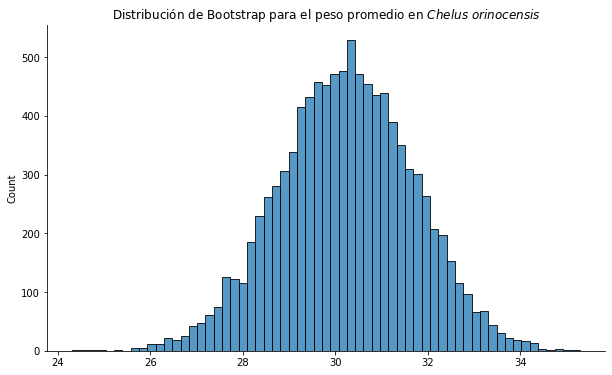

In [25]:
plt.figure(figsize=(10,6))
sns.histplot(peso_boots)
sns.despine()
plt.title('Distribución de Bootstrap para el peso promedio en $Chelus\ orinocensis$')
plt.show()

In [26]:
# Límite inferior (Percentil 2.5%)
inf = np.percentile(peso_boots, 2.5)

# Límite superior (Percentil 97.5%)
sup = np.percentile(peso_boots, 97.5)

In [29]:
print(f'[{inf}, {sup}]')

[27.36428571428571, 33.05017857142857]


Construya el intervalo de confianza del 99% usando el método de
los percentiles:

In [79]:
np.random.choice(chelus['measurementValue'], size=3, replace=True)

array([39.3, 34. , 27.7])

In [32]:
inf99 = np.percentile(peso_boots, 0.5)

sup99 = np.percentile(peso_boots, 99.5)

In [33]:
print(f'[{inf99}, {sup99}]')

[26.392857142857142, 33.935749999999985]
